# Plot Venn Diagrams between 2 experiments

Experiments
* Handpicked 37 jets (Guo et al. 2022)
* Fontanka (Galitsyna et al., 2023) 
* Fun (Liu et al., 2024) 
* MIA-Jet 

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels
from notebooks.func_pileup import *

import os
import pandas as pd
import bioframe as bf
import numpy as np
import yaml

# Across all experiments

Processing experiment: GM12878_microc_Wu-2025_GSE225201_hg38_25kb
* Selected MIA-Jet summary table: GM12878_microc_Wu-2025_GSE225201_hg38_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 387/387 [00:19<00:00, 19.58it/s]


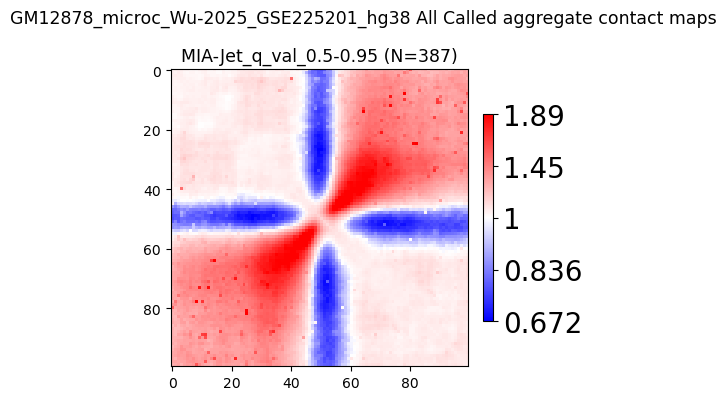

Processing experiment: GM12878_insitu-hic_4DNFI1UEG1HD_25kb
* Selected MIA-Jet summary table: GM12878_insitu-hic_4DNFI1UEG1HD_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 376/376 [00:15<00:00, 23.90it/s]


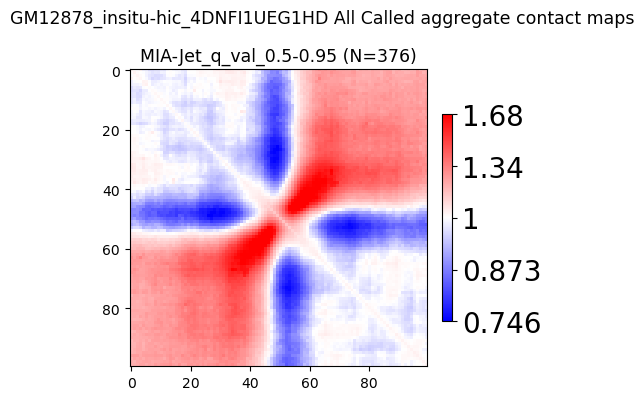

Processing experiment: GM12878_intacthic_ENCFF318GOM_25kb
* Selected MIA-Jet summary table: GM12878_intacthic_ENCFF318GOM_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 359/359 [00:41<00:00,  8.60it/s]


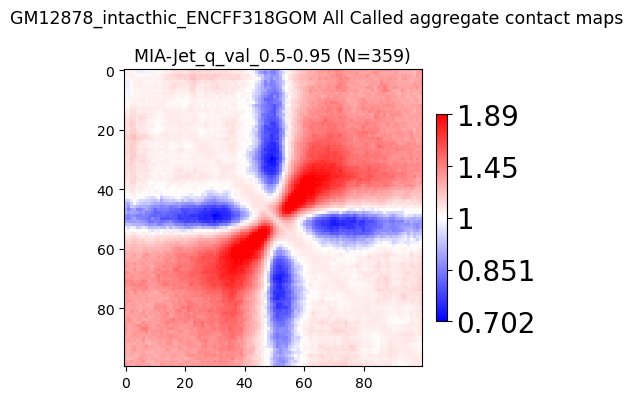

Processing experiment: GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
* Selected MIA-Jet summary table: GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 99/99 [00:01<00:00, 78.06it/s]


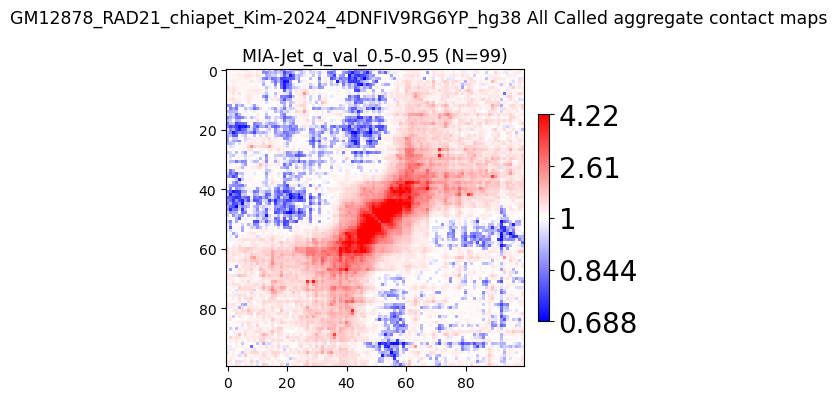

Processing experiment: GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
* Selected MIA-Jet summary table: GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 58/58 [00:00<00:00, 110.92it/s]


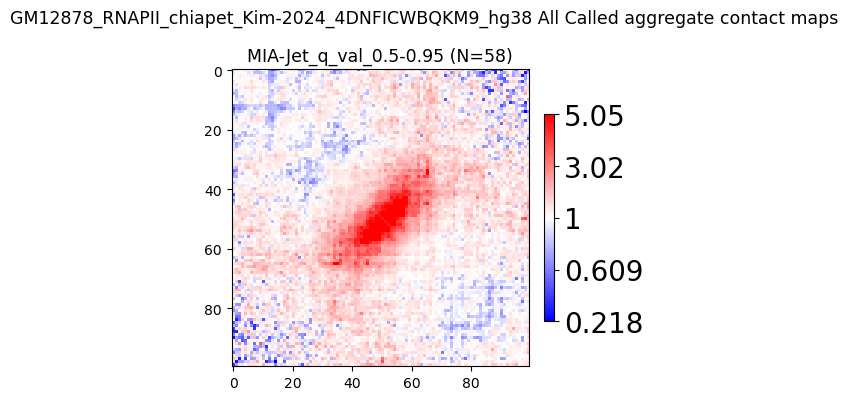

Processing experiment: GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb
* Selected MIA-Jet summary table: GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_chr_combined_q_val_0.5-0.95_25Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 117/117 [00:01<00:00, 116.56it/s]


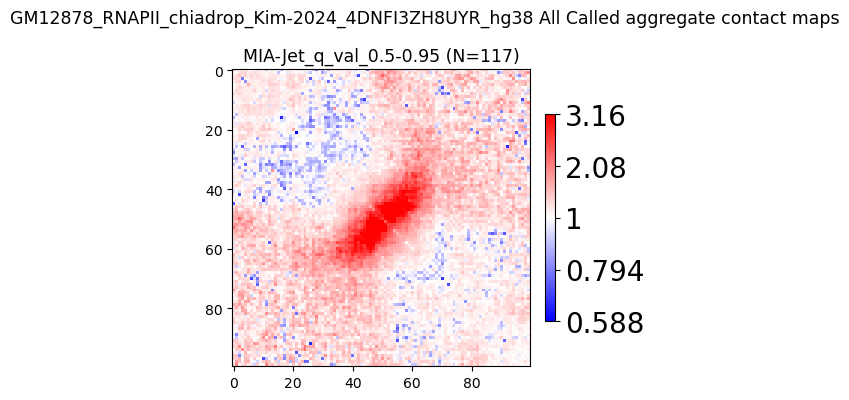

In [2]:
# Load config
config_yaml = """
  GM12878_microc_Wu-2025_GSE225201_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_microc_Wu-2025_GSE225201_hg38.hic"
    genome: "hg38"
    norm: "KR"
    res: "25000"
    exp: "hic"
    # mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_microc_Wu-2025_GSE225201_hg38.ice.mcool" # Not downloaded but possible
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    # chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    # chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    # extra_args:
    # - "--diagnostic_plots"

  GM12878_insitu-hic_4DNFI1UEG1HD_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.hic"
    genome: "hg38"
    norm: "VC_SQRT" # CHANGED from KR to VC_SQRT because chr7 failed
    res: "25000"
    exp: "hic"
    # mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_microc_Wu-2025_GSE225201_hg38.ice.mcool" # Not downloaded but possible
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    extra_args:
    - "--diagnostic_plots"

  GM12878_intacthic_ENCFF318GOM_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_intacthic_ENCFF318GOM.hic"
    genome: "hg38"
    norm: "VC_SQRT"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_intacthic_ENCFF785BPC.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    # chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    # chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    # extra_args:
    # - "--diagnostic_plots"

  GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilabs/downloaded_data/GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"
    # chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    # chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    # extra_args:
    # - "--diagnostic_plots"

  GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"
    # chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    # chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    # extra_args:
    # - "--diagnostic_plots"


  GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"
    # chip_file: '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_Early_repliseq_R1_4DNFI6TILWWX_hg38.bedGraph'
    # chrom_size_file: "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"
    # extra_args:
    # - "--diagnostic_plots"
"""
samples = yaml.safe_load(config_yaml)

# Analysis parameters
output_name = "v2.0.3"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/revision2"

os.makedirs(save_path, exist_ok=True)

# Pileup parameters
data_type = "oe"
expected_stack_size = 100

for key, attributes in samples.items():
    print(f"Processing experiment: {key}")

    hic_file = attributes["file"]

    if "q_val" in attributes.keys():
        q_val_str = f"q_val_{attributes['q_val']}"
    else:
        q_val_str = "q_val_0.1" # default

    if "q_val_white" in attributes.keys():
        q_val_white_str = f"{q_val_str}-{attributes['q_val_white']}"
    elif attributes['exp'] == "replihic" or "compartment" in attributes.keys() and attributes['compartment'] == "False":
        q_val_white_str = f"{q_val_str}" # no white q-value
    else:
        q_val_white_str = f"{q_val_str}-0.95" # default


    basename_hic = os.path.basename(hic_file)
    data_name_hic = os.path.splitext(basename_hic)[0]

    data_name = data_name_hic

    resolution = int(attributes["res"])
    normalization = attributes["norm"]
    genome = attributes["genome"]

    # Standardize normalization to "VC_SQRT" due to hicstraw reading in issues
    # However, if "NONE" then keep it as is
    print("\tWarning: standardizing normalization to 'VC_SQRT' (if not 'NONE') for hicstraw compatibility")
    if normalization == "VC":
        pass # Then continue because these are the downsampled files
    elif normalization != "NONE":
        normalization = "VC_SQRT"


    # MIA-JET
    # The result_type will change across different files
    hic_name = os.path.basename(hic_file).split(".hic")[0]
    folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution)}"
    prefix = f"{hic_name}_chr_combined_"
    suffix = f"_{genomic_labels(resolution)}_summary_table.csv"
    fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_white_str in f)
    print(f"* Selected MIA-Jet summary table: {fname}")
    result_type = fname[len(prefix):-len(suffix)]
    f_pred_miajet_summary = os.path.join(folder, fname)
    f_pred_miajet_expanded = os.path.join(folder, f"{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv")

    # Load it in
    miajet_positions = pd.read_csv(f_pred_miajet_expanded, comment="#")
    miajet_table = pd.read_csv(f_pred_miajet_summary, comment="#")

    chrom_sizes = bf.fetch_chromsizes(genome, as_bed=True)
    common_chroms = chrom_sizes["chrom"].tolist()

    miajet_table = miajet_table[miajet_table["chrom"].isin(common_chroms)]

    print(f"Common chromosomes: {common_chroms}")

    # Combine
    positions = [miajet_positions]
    tables = [miajet_table]
    names = [f"MIA-Jet_{result_type}"]

    bed_tables = []
    for i, (s, e) in enumerate(zip(tables, positions)):
        bed_tables.append(generate_bed_2(s, e, eps=500e3, fraction=1.5))

    if data_type == "observed":
        cmap = "Reds"
        vcenter = None
    else:
        cmap = "bwr"
        vcenter = 1


    # PLOT ALL CALLED
    agg_map = []
    vmaxes = []
    df_stack = []
    for bed_df in bed_tables:
        # Get pileups for each bed_df
        s, d, r = get_pileups_dynamic_resolution(
            hic_file=hic_file,
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes,
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        a = np.mean(s, axis=0)
        vm = np.percentile(a, 99) if np.percentile(a, 99) > np.nanmin(a) else np.nanmax(a)
        vmaxes.append(vm)  # store the 99th percentile for color scaling
        agg_map.append(a)  # average over all stacks
        df_stack.append(d)  # store the DataFrame for later use

    titles = [f"{names[i]} (N={len(df_stack[i])})" for i in range(len(names))]


    plot_n_hic(
        agg_map,
        suptitle=f"{data_name} All Called aggregate contact maps",
        resolution=None,
        cmap_label=None,
        titles=titles,
        cmap=cmap,
        vcenter=vcenter,
        standardize_cbar=True,
        show=True,
        vmax=vmaxes,
        ppr=4,
        # savepath=f"{save_path}/{data_name}_{resolution}_MIA-Jet_{result_type}_all_agg_map-{data_type}.png",
        cbar_fontsize=20,
    )